In [1771]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
import seaborn as sns
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF

In [1772]:
K = 2
T = 200
theta_true = np.random.sample(K)
theta_true /= theta_true.sum()

In [1773]:
means= [(0, 0), 
        (1, 1), 
        (1, 0), 
        (0, 1), 
        (-1, 0), 
        (0, -1), 
        (-1, -1), 
        (1, -1), 
        (-1, 1)]
sigmas = np.random.sample(K)

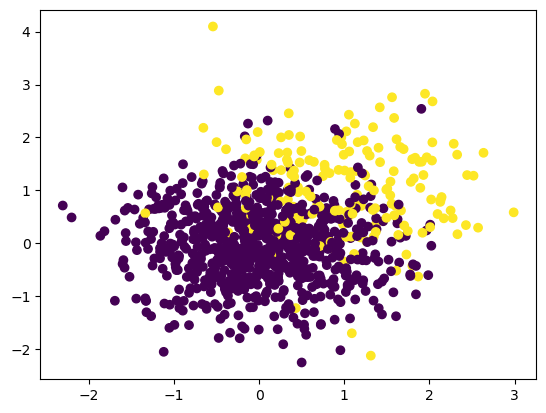

In [1774]:
#X_1 = np.random.multivariate_normal(mean=(0, 0), cov=np.eye(2)*1.2, size=100)
#X_2 = np.random.multivariate_normal(mean=[1, 1], cov=np.eye(2)*1.5, size=100)
X = np.zeros(2000).reshape((1000, 2))
y = np.zeros(1000)
for i in range(1000):
    k = np.random.choice(K, p=theta_true)
    y[i] = k
    X[i,:] = np.random.multivariate_normal(mean=means[k], cov=np.eye(2)*sigmas[k], size=1)[0]

plt.scatter(X[:,0], X[:,1], c=y)

In [1775]:
K = 3
theta_true = np.random.sample(K)
theta_true /= theta_true.sum()
theta_true[0] = 0.9 
theta_true[1] = 0.8
theta_true[2] = 0.7

In [1776]:
theta_true

array([0.9, 0.8, 0.7])

In [1777]:
from scipy.stats import beta

In [1778]:
np.random.choice(l, 3)

array([927, 455, 574])

In [1779]:
theta_hat_TS_1_f[np.random.choice(l, 3),[0,1,2]]

array([0.97543511, 0.52672702, 0.33423824])

In [1780]:
theta_hat_TS_1_f[np.random.choice(l, K),np.arange(K)]

array([0.97543511, 0.51230462, 0.33262764])

In [1355]:
results_TS = defaultdict(list)
results_TS_1 = defaultdict(list)
results_Rand = defaultdict(list)
results_G = defaultdict(list)
results_P = defaultdict(list)
T = 100
rho = T*.5
S = 1000
for l in [1000]:

    for s in range(S):

        alpha_TS = np.random.randint(1, 10, size=K)
        beta_TS =np.random.randint(1, 10, size=K)

        #alpha_TS_1 = alpha_TS.copy()
        #beta_TS_1 = beta_TS.copy()
        
        alpha_TS_1 = np.random.randint(1, 10, size=K)
        beta_TS_1 = np.random.randint(1, 10, size=K)

        alpha_G = np.random.randint(1, 10, size=K)
        beta_G = np.random.randint(1, 10, size=K)

        #theta_true = np.random.sample(K)
        theta_max = np.max(theta_true)

        rw_rand = 0
        rw_TS = 0
        rw_TS_1 = 0
        rw_G = 0
        rw_P = 0

        tao_G = np.nan
        tao_TS = np.nan
        tao_TS_1 = np.nan
        tao_rand = np.nan
        tao_P = np.nan
        
        
        theta_hat_TS_1_f = np.random.rand(l, K)#np.random.beta(size=(l, K), a=alpha_TS_1, b=beta_TS_1)

        for t in range(T):

            theta_hat_G = alpha_G / (alpha_G + beta_G)
            theta_hat_TS = np.random.beta(alpha_TS, beta_TS)
            #theta_hat_TS_1 = np.random.beta(size=(l, K), a=alpha_TS_1, b=beta_TS_1).max(0)
            #theta_hat_TS_1 = theta_hat_TS_1_f[np.random.choice(l),:]
            #theta_hat_TS_1_f = (np.random.beta(size=(l, K), a=alpha_TS_1, b=beta_TS_1)*.01 + 
            #                    theta_hat_TS_1_f[np.random.choice(l, K),np.arange(K)]*.99)
            theta_hat_TS_1 = theta_hat_TS_1_f[np.random.choice(l, K),np.arange(K)]

            x_TS_t = np.argmax(theta_hat_TS)
            x_TS_1_t = np.argmax(theta_hat_TS_1)
            x_G_t = np.argmax(theta_hat_G)
            x_rand_t = np.random.randint(K)

            regret_TS_t = theta_max - theta_true[x_TS_t]#np.max(theta_hat_TS)    
            regret_TS_1_t = theta_max - theta_true[x_TS_1_t]#np.max(theta_hat_TS_1)    
            regret_G_t = theta_max - theta_true[x_G_t]#np.max(theta_hat_G)
            regret_rand_t = theta_max - theta_true[x_rand_t]#np.max(theta_hat_G)

            r_TS_t = np.random.binomial(1, theta_true[x_TS_t])
            r_TS_1_t = np.random.binomial(1, theta_true[x_TS_1_t])
            r_G_t = np.random.binomial(1, theta_true[x_G_t])
            r_rand_t = np.random.binomial(1, theta_true[x_rand_t])
            r_P_t = np.random.binomial(1, theta_max)

            alpha_TS[x_TS_t] += r_TS_t
            beta_TS[x_TS_t] += 1 - r_TS_t

            alpha_TS_1[x_TS_1_t] += r_TS_1_t
            beta_TS_1[x_TS_1_t] += 1 - r_TS_1_t
            w_y = beta.pdf(np.clip(theta_hat_TS_1_f, 1e-10, 1-1e-10), alpha_TS_1, beta_TS_1)
             
            w = w_y / w_y.sum(0)
            if np.isnan(w.sum()):
                print(w_y.sum(0))
            th1 = np.random.choice(theta_hat_TS_1_f[:,0], size=(l,1), p=w[:,0])
            th2 = np.random.choice(theta_hat_TS_1_f[:,1], size=(l,1), p=w[:,1])
            th3 = np.random.choice(theta_hat_TS_1_f[:,2], size=(l,1), p=w[:,2])
            theta_hat_TS_1_f = np.concatenate([th1,th2,th3], axis=1)

            alpha_G[x_G_t] += r_G_t
            beta_G[x_G_t] += 1 - r_G_t

            rw_TS += r_TS_t
            rw_TS_1 += r_TS_1_t
            rw_G += r_G_t
            rw_rand += r_rand_t
            rw_P += r_P_t

            if rw_TS >= rho and np.isnan(tao_TS):
                tao_TS = t

            if rw_TS_1 >= rho and np.isnan(tao_TS_1):
                tao_TS_1 = t

            if rw_rand >= rho and np.isnan(tao_rand):
                tao_rand = t

            if rw_G >= rho and np.isnan(tao_G):
                tao_G = t
                
            if rw_P >= rho and np.isnan(tao_P):
                tao_P = t

            results_TS['s'].append(s)
            results_TS['t'].append(t)
            results_TS['a'].append(x_TS_t)
            results_TS['rw'].append(rw_TS)
            results_TS['regret_t'].append(regret_TS_t)

            results_TS_1['s'].append(s)
            results_TS_1['t'].append(t)
            results_TS_1['a'].append(x_TS_1_t)
            results_TS_1['rw'].append(rw_TS_1)
            results_TS_1['regret_t'].append(regret_TS_1_t)

            results_G['s'].append(s)
            results_G['t'].append(t)
            results_G['a'].append(x_G_t)
            results_G['regret_t'].append(regret_G_t)
            results_G['rw'].append(rw_G)

            results_Rand['s'].append(s)
            results_Rand['t'].append(t)
            results_Rand['a'].append(x_rand_t)
            results_Rand['regret_t'].append(regret_rand_t)
            results_Rand['rw'].append(rw_rand)
            
            results_P['s'].append(s)
            results_P['t'].append(t)
            results_P['a'].append(0)
            results_P['regret_t'].append(0)
            results_P['rw'].append(rw_P)

        results_TS['tao'].append(tao_TS)
        results_TS_1['tao'].append(tao_TS_1)
        results_G['tao'].append(tao_G)
        results_Rand['tao'].append(tao_rand)
        results_P['tao'].append(tao_P)
        
        results_TS['alpha'].append(alpha_TS)
        results_TS_1['alpha'].append(alpha_TS_1)
        results_G['alpha'].append(alpha_G)
    
        results_TS['beta'].append(beta_TS)
        results_TS_1['beta'].append(beta_TS_1)
        results_G['beta'].append(beta_G)
        
        results_TS_1['theta_hat_f'].append(theta_hat_TS_1_f)
        
        if s / 100 == s // 100:
            print(t)
            print(s)

    print((np.array(results_TS['tao']).mean(),
     np.array(results_TS_1['tao']).mean(),
     np.array(results_G['tao']).mean(),
    np.array(results_Rand['tao']).mean()))

99
0
99
100
99
200
99
300
99
400
99
500
99
600
99
700
99
800
99
900
(59.695, 61.013, 61.189, 61.565)


In [1356]:
print((np.array(results_TS['tao']).mean(),
     np.array(results_TS_1['tao']).mean(),
     np.array(results_G['tao']).mean(),
    np.array(results_Rand['tao']).mean(),
     np.array(results_P['tao']).mean()))

(59.695, 61.013, 61.189, 61.565, 54.578)


In [1420]:
results_TS = defaultdict(list)
results_Rand = defaultdict(list)
results_G = defaultdict(list)
results_P = defaultdict(list)
T = 100
rho = T*.5
S = 1000
for s in range(S):

    alpha_TS = np.random.rand(K)#np.random.randint(1, 10, size=K)
    beta_TS = np.random.rand(K)#np.random.randint(1, 10, size=K)

    alpha_G = np.random.rand(K)#np.random.randint(1, 10, size=K)
    beta_G = np.random.rand(K)#np.random.randint(1, 10, size=K)

    #theta_true = np.random.sample(K)
    theta_max = np.max(theta_true)

    rw_rand = 0
    rw_TS = 0
    rw_G = 0
    rw_P = 0

    tao_G = np.nan
    tao_TS = np.nan
    tao_TS_1 = np.nan
    tao_rand = np.nan
    tao_P = np.nan

    for t in range(T):

        theta_hat_G = alpha_G / (alpha_G + beta_G)
        theta_hat_TS = np.random.beta(alpha_TS, beta_TS)

        x_TS_t = np.argmax(theta_hat_TS)
        x_G_t = np.argmax(theta_hat_G)
        x_rand_t = np.random.randint(K)

        regret_TS_t = theta_max - theta_true[x_TS_t]#np.max(theta_hat_TS)    
        regret_G_t = theta_max - theta_true[x_G_t]#np.max(theta_hat_G)
        regret_rand_t = theta_max - theta_true[x_rand_t]

        r_TS_t = np.random.binomial(1, theta_true[x_TS_t])
        r_G_t = np.random.binomial(1, theta_true[x_G_t])
        r_rand_t = np.random.binomial(1, theta_true[x_rand_t])
        r_P_t = np.random.binomial(1, theta_max)

        alpha_TS[x_TS_t] += r_TS_t
        beta_TS[x_TS_t] += 1 - r_TS_t


        alpha_G[x_G_t] += r_G_t
        beta_G[x_G_t] += 1 - r_G_t

        rw_TS += r_TS_t
        rw_G += r_G_t
        rw_rand += r_rand_t
        rw_P += r_P_t

        if rw_TS >= rho and np.isnan(tao_TS):
            tao_TS = t

        if rw_TS_1 >= rho and np.isnan(tao_TS_1):
            tao_TS_1 = t

        if rw_rand >= rho and np.isnan(tao_rand):
            tao_rand = t

        if rw_G >= rho and np.isnan(tao_G):
            tao_G = t
            
        if rw_P >= rho and np.isnan(tao_P):
                tao_P = t

        results_TS['s'].append(s)
        results_TS['t'].append(t)
        results_TS['a'].append(x_TS_t)
        results_TS['rw'].append(rw_TS)
        results_TS['r_t'].append(r_TS_t)
        results_TS['regret_t'].append(regret_TS_t)

        results_G['s'].append(s)
        results_G['t'].append(t)
        results_G['a'].append(x_G_t)
        results_G['regret_t'].append(regret_G_t)
        results_G['rw'].append(rw_G)
        results_G['r_t'].append(r_G_t)

        results_Rand['s'].append(s)
        results_Rand['t'].append(t)
        results_Rand['a'].append(x_rand_t)
        results_Rand['rw'].append(rw_rand)
        results_Rand['r_t'].append(r_rand_t)
        
        results_P['s'].append(s)
        results_P['t'].append(t)
        results_P['a'].append(0)
        results_P['regret_t'].append(0)
        results_P['rw'].append(rw_P)
        results_P['r_t'].append(r_P_t)

    results_TS['tao'].append(tao_TS)
    results_G['tao'].append(tao_G)
    results_Rand['tao'].append(tao_rand)
    results_P['tao'].append(tao_P)
    
    #results_TS['alpha'].append(alpha_TS)
    #results_G['alpha'].append(alpha_G)
    
    #results_TS['beta'].append(beta_TS)
    #results_G['beta'].append(beta_G)
        
    if s / 100 == s // 100:
        #print(t)
        print(s)

#print((np.array(results_P['tao']).mean(),
#       np.array(results_TS['tao']).mean(),
#     np.array(results_G['tao']).mean(),
#    np.array(results_Rand['tao']).mean()))

0
100
200
300
400
500
600
700
800
900


In [1424]:
np.array(results_P['tao']).mean()

54.63

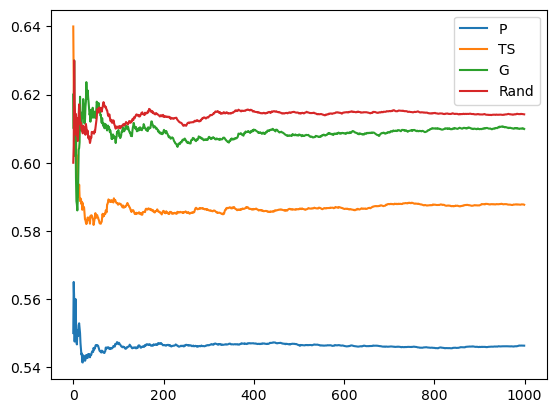

In [1421]:
plt.plot((np.array(results_P['tao']).cumsum() / (np.arange(S) + 1)) / T, label='P')
plt.plot((np.array(results_TS['tao']).cumsum() / (np.arange(S) + 1)) / T, label='TS')
#plt.plot((np.array(results_TS_1['tao']).cumsum() / (np.arange(S) + 1)) / T, label='TS_1')
plt.plot((np.array(results_G['tao']).cumsum() / (np.arange(S) + 1)) / T, label='G')
plt.plot((np.array(results_Rand['tao']).cumsum() / (np.arange(S) + 1)) / T, label='Rand')
plt.legend()

In [1384]:
del results_TS['tao']
del results_TS_1['tao']
del results_G['tao']
del results_Rand['tao']

In [1385]:
del results_TS['alpha']
del results_G['alpha']

del results_TS['beta']
del results_G['beta']

del results_TS_1['alpha']
del results_TS_1['beta']


KeyError: 'alpha'

In [1391]:
del results_TS['beta_TS']

In [1403]:
probs_P['r_t']

0      0.895
1      0.908
2      0.886
3      0.910
4      0.907
       ...  
995    0.919
996    0.901
997    0.901
998    0.896
999    0.911
Name: r_t, Length: 1000, dtype: float64

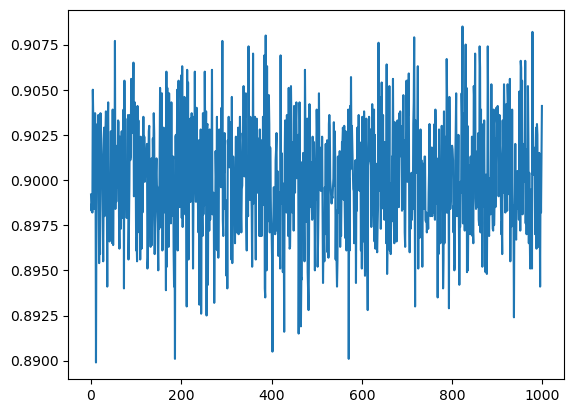

In [1426]:
plt.plot(np.random.binomial(1, .9, (10000, 1000)).mean(0))

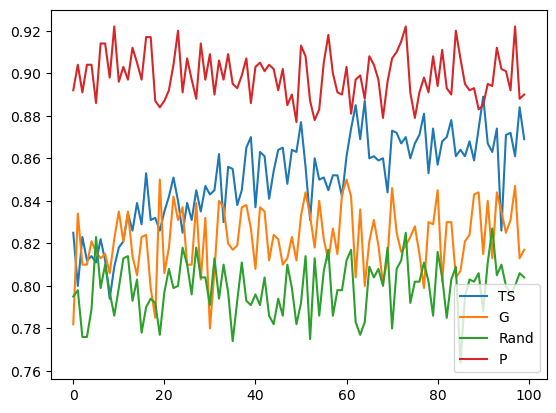

In [1418]:
probs_TS = (pd.DataFrame(results_TS).groupby(['t']).mean()).reset_index()#.sum(1)
#probs_TS_1 = (pd.DataFrame(results_TS_1).groupby(['t']).mean()).reset_index()#.sum(1)
probs_G = (pd.DataFrame(results_G).groupby(['t']).mean()).reset_index()#.sum(1)
probs_Rand = (pd.DataFrame(results_Rand).groupby(['t']).mean()).reset_index()#.sum(1)
probs_P = (pd.DataFrame(results_P).groupby(['t']).mean()).reset_index()#.sum(1)

plt.plot(probs_TS['t'], probs_TS['r_t'], label='TS')
#plt.plot(probs_TS_1['t'], 1 - probs_TS_1['rw'] / (probs_TS_1['t'] + 1), label='TS_1')
plt.plot(probs_G['t'], probs_G['r_t'], label='G')
plt.plot(probs_Rand['t'], probs_Rand['r_t'], label='Rand')
plt.plot(probs_P['t'], probs_P['r_t'], label='P')
#plt.plot(probs_TS['t'], 1 - probs_TS['t'] / (probs_TS['t'] + 1), label='Perfect')
plt.legend()

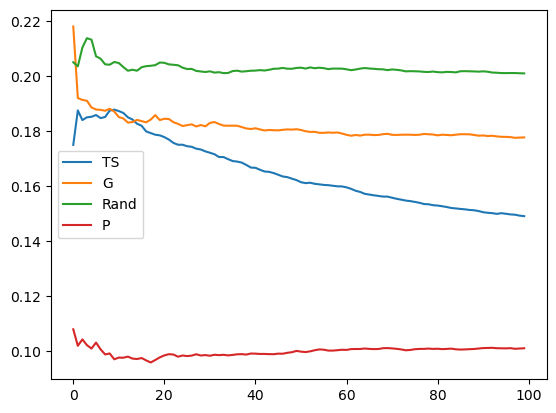

In [1419]:
probs_TS = (pd.DataFrame(results_TS).groupby(['t']).mean()).reset_index()#.sum(1)
#probs_TS_1 = (pd.DataFrame(results_TS_1).groupby(['t']).mean()).reset_index()#.sum(1)
probs_G = (pd.DataFrame(results_G).groupby(['t']).mean()).reset_index()#.sum(1)
probs_Rand = (pd.DataFrame(results_Rand).groupby(['t']).mean()).reset_index()#.sum(1)
probs_P = (pd.DataFrame(results_P).groupby(['t']).mean()).reset_index()#.sum(1)

plt.plot(probs_TS['t'], 1 - probs_TS['rw'] / (probs_TS['t'] + 1), label='TS')
#plt.plot(probs_TS_1['t'], 1 - probs_TS_1['rw'] / (probs_TS_1['t'] + 1), label='TS_1')
plt.plot(probs_G['t'], 1 - probs_G['rw'] / (probs_G['t'] + 1), label='G')
plt.plot(probs_Rand['t'], 1 - probs_Rand['rw'] / (probs_Rand['t'] + 1), label='Rand')
plt.plot(probs_P['t'], 1 - probs_P['rw'] / (probs_P['t'] + 1), label='P')
#plt.plot(probs_TS['t'], 1 - probs_TS['t'] / (probs_TS['t'] + 1), label='Perfect')
plt.legend()
#    plt.ylim((0,1))

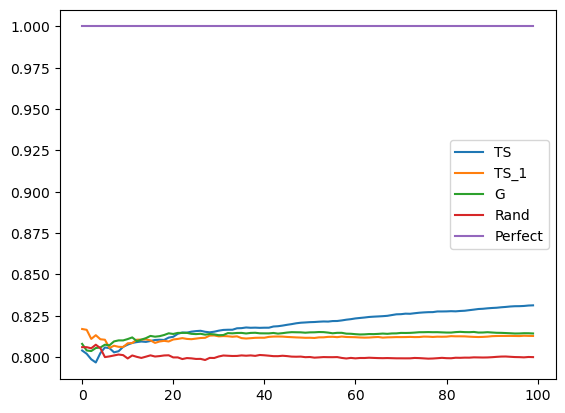

In [1348]:
probs_TS = (pd.DataFrame(results_TS).groupby(['t']).mean()).reset_index()#.sum(1)
probs_TS_1 = (pd.DataFrame(results_TS_1).groupby(['t']).mean()).reset_index()#.sum(1)
probs_G = (pd.DataFrame(results_G).groupby(['t']).mean()).reset_index()#.sum(1)
probs_Rand = (pd.DataFrame(results_Rand).groupby(['t']).mean()).reset_index()#.sum(1)

plt.plot(probs_TS['t'], probs_TS['rw'] / (probs_TS['t'] + 1), label='TS')
plt.plot(probs_TS_1['t'], probs_TS_1['rw'] / (probs_TS_1['t'] + 1), label='TS_1')
plt.plot(probs_G['t'], probs_G['rw'] / (probs_G['t'] + 1), label='G')
plt.plot(probs_Rand['t'], probs_Rand['rw'] / (probs_Rand['t'] + 1), label='Rand')
plt.plot(probs_TS['t'], (probs_TS['t'] + 1) / (probs_TS['t'] + 1), label='Perfect')
plt.legend()
#    plt.ylim((0,1))

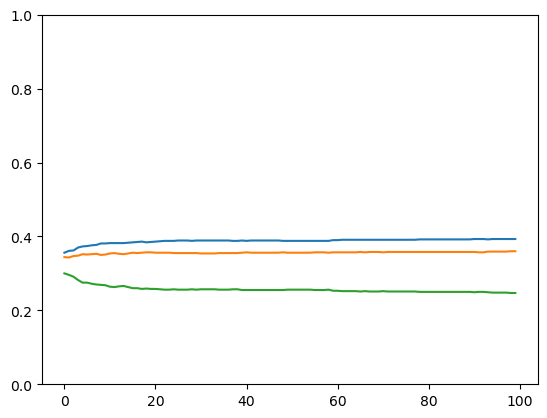

In [1349]:
probs = (pd.DataFrame(results_G).groupby(['a','t']).count() / S).reset_index()#.sum(1)
probs = probs.drop(columns=['regret_t'])
for k in range(K):
    probs_k = probs.query('a == @k')
    plt.plot(probs_k['t'], probs_k['s'])
    plt.ylim((0,1))

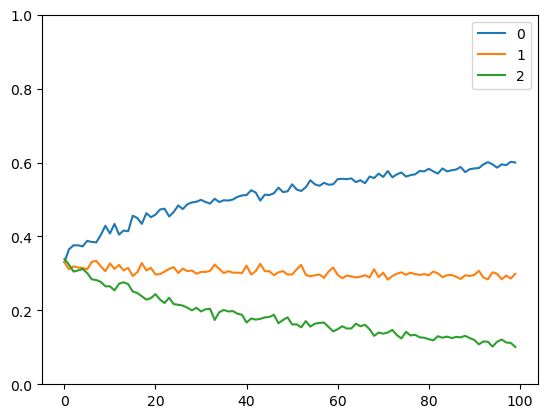

In [1350]:
probs = (pd.DataFrame(results_TS).groupby(['a','t']).count() / S).reset_index()#.sum(1)
for k in range(K):
    probs_k = probs.query('a == @k')
    plt.plot(probs_k['t'], probs_k['s'], label=k)
    plt.ylim((0,1))
    plt.legend()

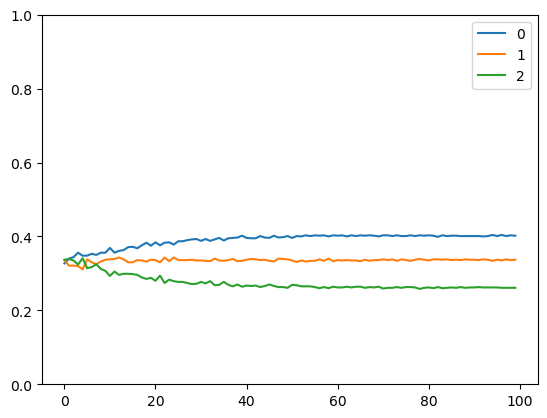

In [1351]:
probs = (pd.DataFrame(results_TS_1).groupby(['a','t']).count() / S).reset_index()#.sum(1)
for k in range(K):
    probs_k = probs.query('a == @k')
    plt.plot(probs_k['t'], probs_k['s'], label=k)
    plt.ylim((0,1))
plt.legend()

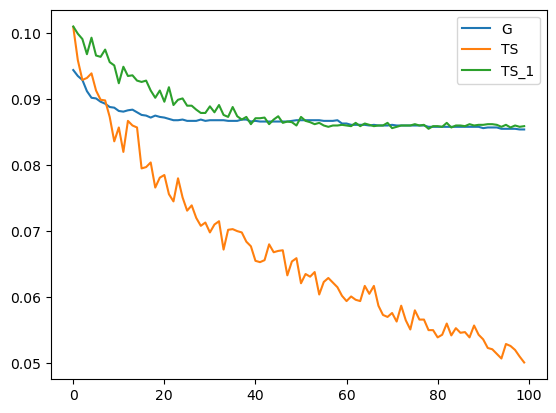

In [1352]:
probs_G = (pd.DataFrame(results_G).groupby(['t']).mean()).reset_index()#.sum(1)
probs_G = probs_G.drop(columns=['s'])

probs_TS = (pd.DataFrame(results_TS).groupby(['t']).mean()).reset_index()#.sum(1)
probs_TS = probs_TS.drop(columns=['s'])

probs_TS_1 = (pd.DataFrame(results_TS_1).groupby(['t']).mean()).reset_index()#.sum(1)
probs_TS_1 = probs_TS_1.drop(columns=['s'])

plt.plot(probs_G['t'],probs_G['regret_t'], label='G')
plt.plot(probs_TS['t'], probs_TS['regret_t'], label='TS')
plt.plot(probs_TS_1['t'], probs_TS_1['regret_t'], label='TS_1')
plt.legend()

In [1869]:
np.concatenate([np.ones((100,1)), 
                                       2*np.ones((50, 1)), 
                                       3*np.ones((30, 1)), 
                                       4*np.ones((10, 1))]).shape

(190, 1)

In [1870]:
S = np.random.multivariate_normal([0,0], np.eye(2), 100)
S = np.concatenate([S, np.random.multivariate_normal([2,2], np.eye(2), 100)])
S = np.concatenate([S, np.random.multivariate_normal([-2,-2], np.eye(2), 50)])
S = np.concatenate([S, np.random.multivariate_normal([-2,2], np.eye(2), 30)])
S = np.concatenate([S, np.random.multivariate_normal([2,-2], np.eye(2), 10)])
S = np.concatenate([S, np.concatenate([np.ones((100,1)), 
                                       2*np.ones((100,1)), 
                                       3*np.ones((50, 1)), 
                                       4*np.ones((30, 1)), 
                                       5*np.ones((10, 1))])], axis=1)

In [1896]:
n_mix = 4
S_list = []
pdf_list = []
size_list = [100,100,50,30,10]
mean_list = [[2,2],[-2,-2],[-2,2],[2,-2]]
sigma_list = [1,.5,1.5,.7,1.2]

for i in range(n_mix):
    mui = 
    sigmai = sigma_list[i]*np.eye(2)
    Si = np.random.multivariate_normal(mean_list[i], sigmai, size_list[i])
    
    Si = np.concatenate([Si, i*np.ones((size_list[i],1))], axis=1)
    pdf_list.append(multivariate_normal(mean=np.zeros(2), cov=sigmai))                     
    S_list.append(Si)
    
S = np.concatenate(S_list)

In [1898]:
for i in range(n_mix):
    Si = np.random.multivariate_normal(mean_list[i], sigma_list[i]*np.eye(2), size_list[i])
    Si = np.concatenate([Si, i*np.ones((size_list[i],1))], axis=1)
                         
    S_list

[array([[ 1.81368162,  1.31916186,  0.        ],
        [ 1.49529765,  2.65236189,  0.        ],
        [ 3.22644278,  2.70153717,  0.        ],
        [ 2.8334825 ,  2.49423124,  0.        ],
        [ 3.11874232,  0.69247468,  0.        ],
        [ 3.02612252,  0.85281202,  0.        ],
        [ 2.56757246,  2.10446665,  0.        ],
        [ 2.08290902,  1.80907309,  0.        ],
        [ 2.27875406,  0.68311637,  0.        ],
        [ 1.27099788, -0.35024192,  0.        ],
        [-0.38731741,  1.9338552 ,  0.        ],
        [ 2.71785382,  2.67346887,  0.        ],
        [ 0.71428364,  1.8174754 ,  0.        ],
        [ 2.02623073,  3.19643333,  0.        ],
        [ 2.47423523,  2.0693373 ,  0.        ],
        [ 1.70122361,  2.21935737,  0.        ],
        [ 2.23261855,  2.89954149,  0.        ],
        [ 2.08945626,  0.39757384,  0.        ],
        [ 3.24768148,  2.73768213,  0.        ],
        [ 0.01294125,  1.25487433,  0.        ],
        [ 2.56696786

In [1883]:
from scipy.stats import multivariate_normal

In [1897]:
S

array([[ 1.81368162,  1.31916186,  0.        ],
       [ 1.49529765,  2.65236189,  0.        ],
       [ 3.22644278,  2.70153717,  0.        ],
       [ 2.8334825 ,  2.49423124,  0.        ],
       [ 3.11874232,  0.69247468,  0.        ],
       [ 3.02612252,  0.85281202,  0.        ],
       [ 2.56757246,  2.10446665,  0.        ],
       [ 2.08290902,  1.80907309,  0.        ],
       [ 2.27875406,  0.68311637,  0.        ],
       [ 1.27099788, -0.35024192,  0.        ],
       [-0.38731741,  1.9338552 ,  0.        ],
       [ 2.71785382,  2.67346887,  0.        ],
       [ 0.71428364,  1.8174754 ,  0.        ],
       [ 2.02623073,  3.19643333,  0.        ],
       [ 2.47423523,  2.0693373 ,  0.        ],
       [ 1.70122361,  2.21935737,  0.        ],
       [ 2.23261855,  2.89954149,  0.        ],
       [ 2.08945626,  0.39757384,  0.        ],
       [ 3.24768148,  2.73768213,  0.        ],
       [ 0.01294125,  1.25487433,  0.        ],
       [ 2.56696786,  1.51080164,  0.   

In [1888]:
rv=multivariate_normal(mean=np.zeros(2), cov=np.eye(2))
rv.pdf(S[:,:2])

array([1.34724515e-01, 1.07675390e-01, 1.49009466e-01, 4.28175413e-02,
       7.67083310e-02, 3.50067241e-02, 1.81380924e-02, 9.91514209e-02,
       1.28821292e-01, 1.45386321e-01, 3.95821651e-02, 4.44819450e-02,
       1.75480838e-02, 1.41218942e-01, 3.33535775e-02, 1.46721366e-01,
       1.49010336e-01, 4.41007356e-02, 2.06530829e-02, 1.05335496e-01,
       5.16302510e-02, 1.24621760e-01, 1.00109825e-01, 3.88725383e-02,
       8.15247061e-02, 2.09513500e-03, 1.36463423e-01, 8.69415365e-02,
       1.05591562e-01, 1.26872395e-01, 1.03914002e-01, 1.10590523e-01,
       1.50395723e-02, 1.12335693e-01, 9.56075889e-02, 1.12739835e-01,
       1.50085761e-01, 3.85492953e-02, 9.92632716e-02, 7.34888935e-02,
       8.03729750e-02, 5.01264010e-02, 5.47613687e-02, 1.48602141e-01,
       1.52518345e-01, 7.65260418e-02, 6.58358182e-02, 6.07102144e-02,
       7.43065107e-02, 1.40138672e-01, 4.73545987e-02, 1.45475651e-01,
       1.03517489e-01, 1.22205150e-01, 1.06381549e-02, 1.28649676e-01,
      

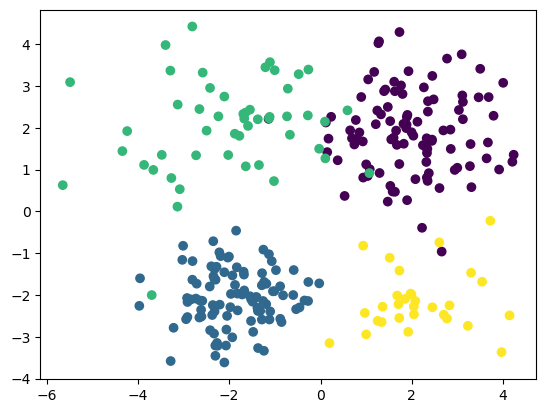

In [1895]:
plt.scatter(S[:, 0],
            S[:, 1], c=S[:, 2])

In [1786]:
kernel = 1.0 * RBF(1.0)
K = kernel(S)
expit = lambda x: 1/(1+np.exp(-x))

(array([19., 13.,  4.,  2.,  7.,  4.,  7.,  4.,  6., 34.]),
 array([2.94463961e-07, 1.00000263e-01, 2.00000232e-01, 3.00000201e-01,
        4.00000170e-01, 5.00000138e-01, 6.00000107e-01, 7.00000076e-01,
        8.00000045e-01, 9.00000014e-01, 9.99999982e-01]),
 <BarContainer object of 10 artists>)

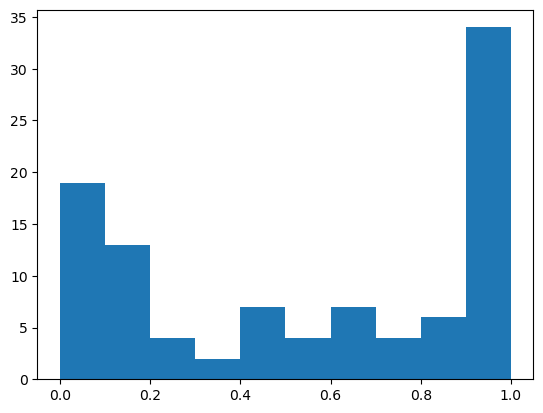

In [1842]:
b = 10
a = 0
x = np.random.multivariate_normal(np.zeros(100), K, 1).reshape((100, 1))
#y = b * x + a #+ np.random.normal(0,1,100).reshape((100, 1))
f = expit(b * x + a)
y = np.random.binomial(1,f).flatten()
x = np.concatenate([np.ones((100, 1)), x], 1)
plt.hist(f)

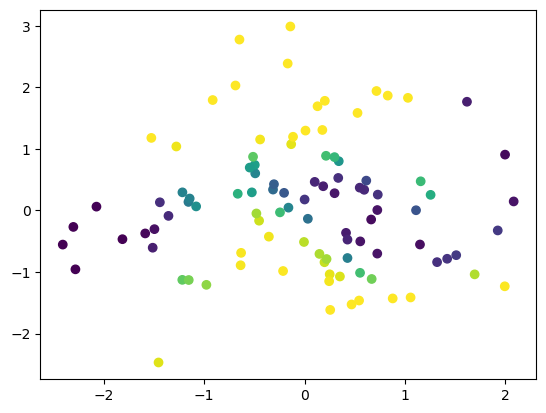

In [1843]:
plt.scatter(S[:, 0],
            S[:, 1], 
            c=f)

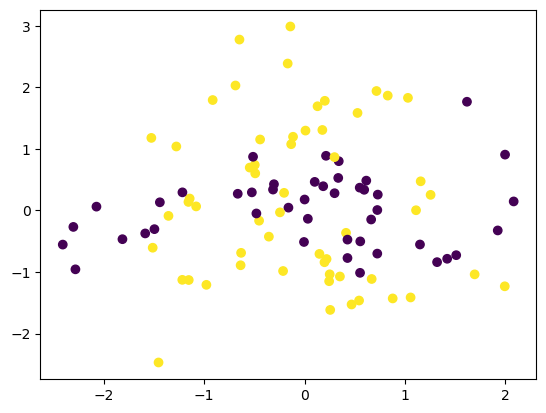

In [1844]:
plt.scatter(S[:, 0],
            S[:, 1], 
            c=y)

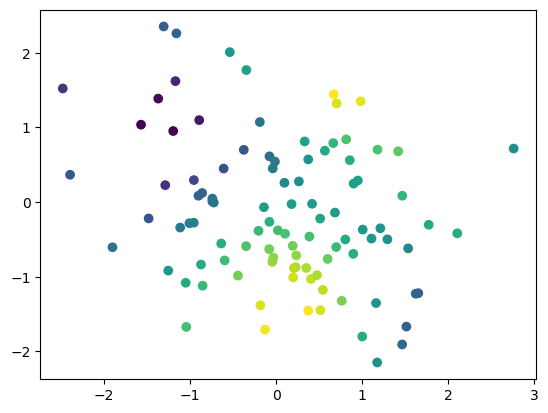

In [730]:
plt.scatter(S[:, 0],
            S[:, 1], 
            c=x[:,-1])

In [568]:
s0 = 1
noise = 1
mu_t = np.zeros(2)
mu_0 = np.zeros(2)
sigma_t = s0 * np.eye(2) 
sigma_0 = s0 * np.eye(2) 
    
f = x
r = y
s_inv = np.linalg.inv(sigma_t)
#ffT = np.outer(f, f)
ffT = np.dot(f.T, f)
sigma_t_ = sigma_t.copy()
sigma_t = sigma_t + ffT
mu_t = np.dot(np.linalg.inv(sigma_t), np.dot(f.T, r) + np.dot(sigma_t, mu_t))
mu_t, sigma_t

(array([[0.8764897 , 0.8764897 ],
        [2.13331444, 2.13331444]]),
 array([[101.        ,  29.27110842],
        [ 29.27110842,  73.39151275]]))

In [569]:
s0 = 1
noise = 1
mu_t = np.zeros(1)
sigma_t = s0 * np.eye(1) 
sigma_t_ = s0 * np.eye(1) 
    
for i in range(100):
    f = x[i, :]
    r = y[i, 0]
    s_inv = np.linalg.inv(sigma_t_)
    ffT = np.outer(f, f)
    mu_t = np.dot(np.linalg.inv(s_inv + ffT), r * f + np.dot(s_inv, mu_t))
    sigma_t = sigma_t + ffT
    sigma_t_ = np.linalg.inv(s_inv + ffT) 

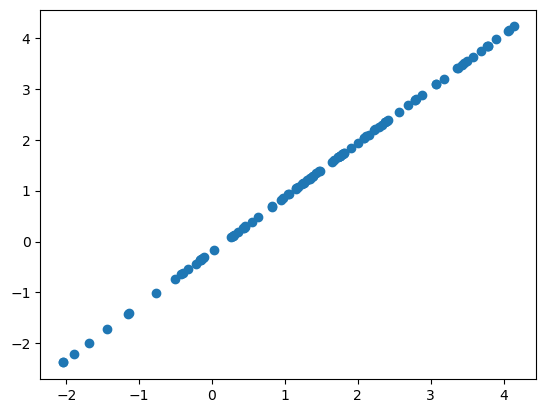

In [735]:
plt.scatter(y, np.dot(x, mu_t) )

In [1671]:
from sklearn.datasets import make_friedman2
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import DotProduct, WhiteKernel
X, y = make_friedman2(n_samples=500, noise=0, random_state=0)
kernel = DotProduct() + WhiteKernel()
train = np.random.choice(500,450,False)
val = np.array(list(set(np.arange(0,500)).difference(train)))

gpr = GaussianProcessRegressor(kernel=kernel,random_state=0).fit(X[train,1:3], y[train])
gpr.score(X[val,1:3], y[val])

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__sigma_0 is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


0.5040883005370274

In [1687]:
y_hat = gpr.predict(X[val,1:3])

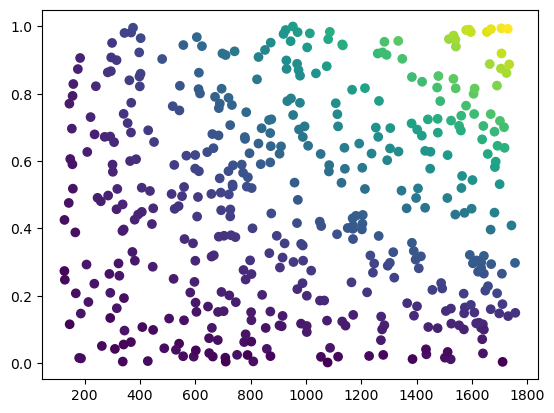

In [1672]:
plt.scatter(X[train,1], X[train,2], c=y[train])

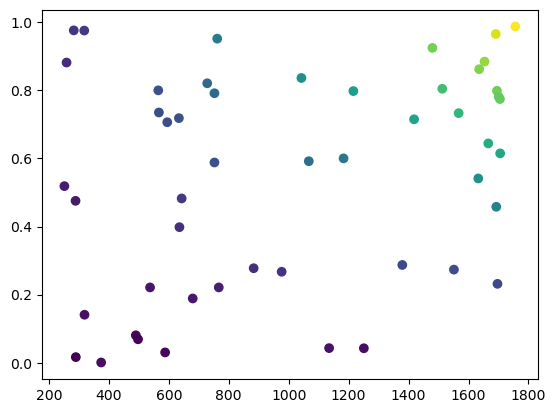

In [1673]:
plt.scatter(X[val,1], X[val,2], c=y[val])

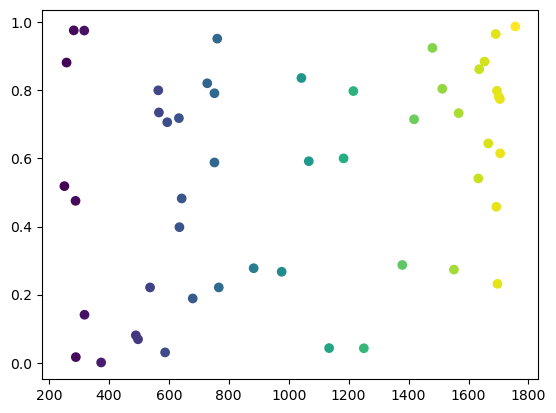

In [1689]:
plt.scatter(X[val,1], X[val,2], c=y_hat)

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_21494/2017700523.py:1: RuntimeWarning: covariance is not positive-semidefinite.
  plt.scatter(X[val,1], X[val,2], c=np.random.multivariate_normal(y_hat, Sigma_star))


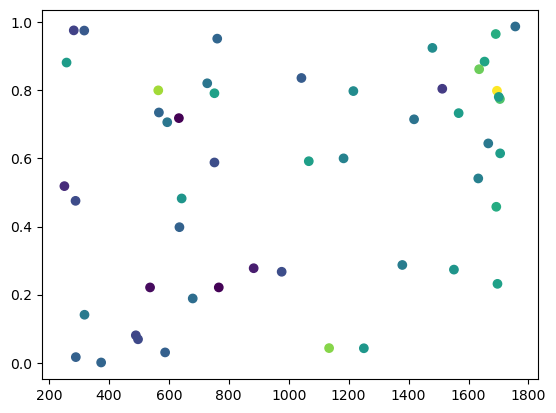

In [1768]:
plt.scatter(X[val,1], X[val,2], c=np.random.multivariate_normal(y_hat, Sigma_star))


In [1674]:
K_y = gpr.kernel_(X[train,1:3])
K_star = gpr.kernel_(X[train,1:3], X[val,1:3])
K_star_star = gpr.kernel_(X[val,1:3])

In [1721]:
X[val,1:3][9]

array([1.75601483e+03, 9.87889169e-01])

In [1718]:
(K_star.T @ np.linalg.inv(K_y) @ y[train])

array([367.89815859, 693.4762893 , 182.81191822, 554.62318982,
       356.15884991, 138.53288341, 833.83171725, 277.30207866,
       521.69986603, 858.68063539, 374.76507138, 276.29016195,
       310.65701131, 367.83704854, 758.31944134, 431.68367119,
       141.51017674, 829.30341311, 833.5106008 , 674.1327905 ,
       123.07077915, 826.79136471, 827.4721491 , 262.67641691,
       808.46947036, 290.89985489, 723.444356  , 594.4871237 ,
       799.67610933, 287.16238636, 739.50789998, 611.30799576,
       578.42640447, 798.10562942, 372.50630184, 828.68704734,
       332.25401246, 239.40435016, 126.73554566, 477.34136788,
       509.78856669, 155.6418244 , 766.18969187, 155.71261438,
       814.45962367, 141.24051058, 831.62430487, 242.99187076,
       309.89908136, 314.32743034])

In [1715]:
np.argmax(K_star.T @ np.linalg.inv(K_y) @ y[train])

9

In [1749]:
np.max(K_star.T @ np.linalg.inv(K_y) @ y[train])

858.6806353859863

In [1745]:
np.argmax(np.random.multivariate_normal(y_hat, Sigma_star))

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_21494/781676003.py:1: RuntimeWarning: covariance is not positive-semidefinite.
  np.argmax(np.random.multivariate_normal(y_hat, Sigma_star))


30

In [1750]:
max_dist = np.zeros(1000)
for i in range(1000):
    max_dist[i] = np.max(np.random.multivariate_normal(y_hat, np.diag(np.diag(Sigma_star))))
max_dist

array([1255.25179619, 1402.71143353, 1320.53889202, 1261.79350923,
       1308.42136692, 1414.3952648 , 1493.88449902, 1397.32296113,
       1342.06717439, 1379.8612397 , 1280.60566749, 1463.35653669,
       1951.49365184, 1357.10492607, 1525.23387056, 1463.62492943,
        967.28774229, 1253.84493076, 1510.79370483, 1615.65682528,
       1502.94660165, 1276.63294837, 1148.48365466, 1440.24498615,
       1389.54271909, 1348.58222778, 1119.85393032, 1532.60483989,
       1336.14837732, 1439.39618305, 1204.96933604, 1248.05266965,
       1336.70397033, 1273.81808121, 1545.27424439, 1324.83703728,
       1450.98855012, 1319.16948784, 1326.40477244, 1356.41985039,
       1314.38491971, 1346.73806653, 1550.23939507, 1452.45037471,
       1237.69910286, 1368.7993178 , 1539.54865065, 1286.85418535,
       1229.09706801, 1313.18771914, 1189.0502722 , 1724.27272038,
       1343.67966701, 1360.96995502, 1625.29182465, 1286.01168895,
       1489.97554164, 1452.948393  , 1699.87739492, 1417.28620

(array([  6.,  37., 151., 219., 254., 179.,  88.,  45.,  17.,   4.]),
 array([ 935.60553248, 1038.16491393, 1140.72429538, 1243.28367683,
        1345.84305828, 1448.40243973, 1550.96182118, 1653.52120263,
        1756.08058408, 1858.63996553, 1961.19934698]),
 <BarContainer object of 10 artists>)

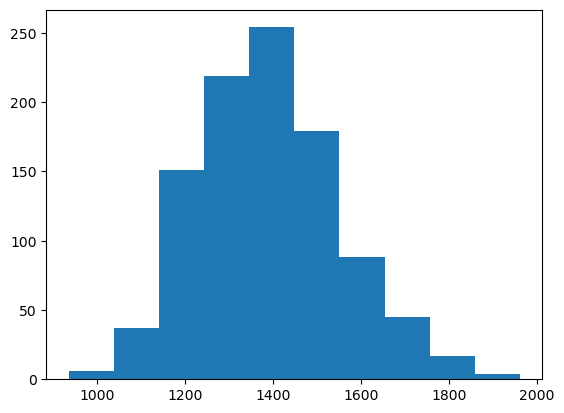

In [1747]:
plt.hist(max_dist)

(array([ 10.,  70., 194., 276., 215., 142.,  57.,  24.,   8.,   4.]),
 array([ 938.07017083, 1048.98823052, 1159.9062902 , 1270.82434989,
        1381.74240957, 1492.66046925, 1603.57852894, 1714.49658862,
        1825.4146483 , 1936.33270799, 2047.25076767]),
 <BarContainer object of 10 artists>)

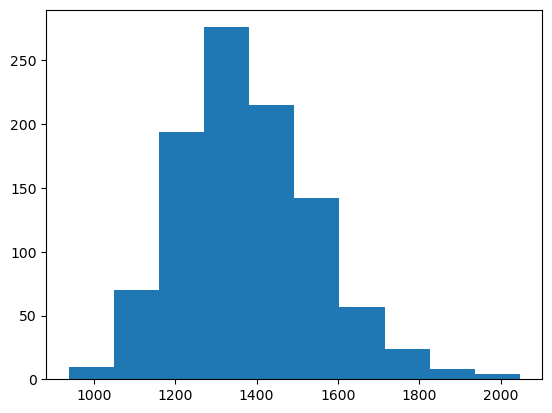

In [1751]:
plt.hist(max_dist)

In [1682]:
Sigma_star = np.round(K_star_star - (K_star.T @ np.linalg.inv(K_y) @ K_star), 4)

In [1692]:
Sigma_star

array([[1.00108740e+05, 2.04679700e+02, 5.38867000e+01, ...,
        7.16511000e+01, 9.16162000e+01, 9.28331000e+01],
       [2.04679700e+02, 1.00385871e+05, 1.01735400e+02, ...,
        1.35220800e+02, 1.72408300e+02, 1.74889600e+02],
       [5.38867000e+01, 1.01735400e+02, 1.00026858e+05, ...,
        3.56853000e+01, 4.53807000e+01, 4.60802000e+01],
       ...,
       [7.16511000e+01, 1.35220800e+02, 3.56853000e+01, ...,
        1.00047418e+05, 6.03446000e+01, 6.12579000e+01],
       [9.16162000e+01, 1.72408300e+02, 4.53807000e+01, ...,
        6.03446000e+01, 1.00077192e+05, 7.82045000e+01],
       [9.28331000e+01, 1.74889600e+02, 4.60802000e+01, ...,
        6.12579000e+01, 7.82045000e+01, 1.00079291e+05]])

In [1685]:
Sigma_star[:5,:5]

array([[1.00108740e+05, 2.04679700e+02, 5.38867000e+01, 1.63499100e+02,
        1.05290200e+02],
       [2.04679700e+02, 1.00385871e+05, 1.01735400e+02, 3.08646500e+02,
        1.98144700e+02],
       [5.38867000e+01, 1.01735400e+02, 1.00026858e+05, 8.14745000e+01,
        5.21559000e+01],
       [1.63499100e+02, 3.08646500e+02, 8.14745000e+01, 1.00247157e+05,
        1.58250000e+02],
       [1.05290200e+02, 1.98144700e+02, 5.21559000e+01, 1.58250000e+02,
        1.00101953e+05]])

<AxesSubplot: >

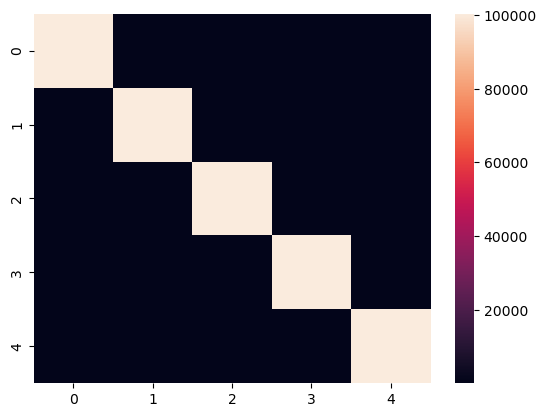

In [1686]:
sns.heatmap(Sigma_star[:5,:5])

In [1427]:
from sklearn.gaussian_process import GaussianProcessRegressor

In [ ]:
results_TS = defaultdict(list)
results_TS_1 = defaultdict(list)
results_Rand = defaultdict(list)
results_G = defaultdict(list)
rho = 50
T = 100
S = 1000

s0 = 1
noise = 1

for l in [1]:

    for s in range(S):
        
        mu_t_TS = np.zeros(2)
        sigma_t_TS = s0 * np.eye(2) 
        sigma_t_TS_ = s0 * np.eye(2) 
        
        mu_t_G = np.zeros(2)
        sigma_t_G = s0 * np.eye(2) 
        sigma_t_G_ = s0 * np.eye(2) 
        
        mu_t_TS_1 = np.zeros(2)
        sigma_t_TS_1 = s0 * np.eye(2) 
        sigma_t_TS_1_ = s0 * np.eye(2) 
  

        #theta_true = np.random.sample(K)
        #theta_max = np.max(theta_true)

        rw_rand = 0
        rw_TS = 0
        rw_TS_1 = 0
        rw_G = 0

        tao_G = np.nan
        tao_TS = np.nan
        tao_TS_1 = np.nan
        tao_rand = np.nan
        
        mask_TS = [False] * 100
        mask_TS_1 = [False] * 100
        mask_G = [False] * 100
        mask_rand = [False] * 100
        
        for t in range(T):

            theta_hat_G = mu_t_G
            theta_hat_TS = np.random.multivariate_normal(mu_t_TS, sigma_t_TS)
            theta_hat_TS = np.random.multivariate_normal(mu_t_TS, sigma_t_TS)
            theta_hat_TS_1 = np.random.multivariate_normal(mu_t_TS, sigma_t_TS, 100)
            
            pred_TS = np.dot(x, theta_hat_TS)
            pred_TS[mask_TS] = np.nan
            
            pred_TS_1 = np.dot(x, theta_hat_TS_1.T).max(1)
            pred_TS_1[mask_TS_1] = np.nan

            pred_G = np.dot(x, theta_hat_G)
            pred_G[mask_G] = np.nan

            x_TS_t = np.nanargmax(pred_TS)
            
            x_TS_1_t = np.nanargmax(pred_TS_1)
            
            x_G_t = np.nanargmax(pred_G)
            
            
            #x_G_t = np.argmax(theta_hat_G)
            x_rand_t = np.random.randint(100)
            
            r_TS_t = y[x_TS_t, 0]
            r_TS_1_t = y[x_TS_1_t, 0]
            #r_TS_1_t = np.random.binomial(1, theta_true[x_TS_1_t])
            r_G_t = y[x_G_t, 0] 
            r_rand_t = y[x_rand_t, 0]
            
            y_TS = y.copy()
            y_TS[mask_TS] = np.nan
            regret_TS_t = np.nanmax(y_TS) - r_TS_t
            
            y_TS_1 = y.copy()
            y_TS_1[mask_TS_1] = np.nan
            regret_TS_1_t = np.nanmax(y_TS_1) - r_TS_1_t
            
            #regret_TS_1_t = theta_max - theta_true[x_TS_1_t]#np.max(theta_hat_TS_1)    
            y_rand = y.copy()
            y_rand[mask_rand] = np.nan
            regret_rand_t = np.nanmax(y_rand) - r_rand_t
            
            y_G = y.copy()
            y_G[mask_G] = np.nan
            regret_G_t = np.nanmax(y_TS) - r_G_t#theta_max - theta_true[x_G_t]#np.max(theta_hat_G)

                
            f = x[x_TS_t, :]
            r = r_TS_t.copy()
            s_inv = np.linalg.inv(sigma_t_TS_)
            ffT = np.outer(f, f)
            mu_t_TS = np.dot(np.linalg.inv(s_inv + ffT), r * f + np.dot(s_inv, mu_t_TS))
            sigma_t_TS = sigma_t_TS + ffT
            sigma_t_TS_ = np.linalg.inv(s_inv + ffT)  
            
            f = x[x_TS_1_t, :]
            r = r_TS_1_t.copy()
            s_inv = np.linalg.inv(sigma_t_TS_1_)
            ffT = np.outer(f, f)
            mu_t_TS_1 = np.dot(np.linalg.inv(s_inv + ffT), r * f + np.dot(s_inv, mu_t_TS_1))
            sigma_t_TS_1 = sigma_t_TS_1 + ffT
            sigma_t_TS_1_ = np.linalg.inv(s_inv + ffT) 
    
            f = x[x_G_t, :]
            r = r_G_t.copy()
            s_inv = np.linalg.inv(sigma_t_G_)
            ffT = np.outer(f, f)
            mu_t_G = np.dot(np.linalg.inv(s_inv + ffT), r * f + np.dot(s_inv, mu_t_G))
            sigma_t_G = sigma_t_G + ffT
            sigma_t_G_ = np.linalg.inv(s_inv + ffT)  
    
            rw_TS += r_TS_t
            rw_TS_1 += r_TS_1_t
            rw_G += r_G_t
            rw_rand += r_rand_t

            if rw_TS >= rho and np.isnan(tao_TS):
                tao_TS = t

            if rw_TS_1 >= rho and np.isnan(tao_TS_1):
                tao_TS_1 = t

            if rw_rand >= rho and np.isnan(tao_rand):
                tao_rand = t

            if rw_G >= rho and np.isnan(tao_G):
                tao_G = t

            results_TS['s'].append(s)
            results_TS['t'].append(t)
            results_TS['a'].append(x_TS_t)
            results_TS['rw'].append(rw_TS)
            results_TS['regret_t'].append(regret_TS_t)

            results_TS_1['s'].append(s)
            results_TS_1['t'].append(t)
            results_TS_1['a'].append(x_TS_1_t)
            results_TS_1['rw'].append(rw_TS_1)
            results_TS_1['regret_t'].append(regret_TS_1_t)

            results_G['s'].append(s)
            results_G['t'].append(t)
            results_G['a'].append(x_G_t)
            results_G['regret_t'].append(regret_G_t)
            results_G['rw'].append(rw_G)

            results_Rand['s'].append(s)
            results_Rand['t'].append(t)
            results_Rand['a'].append(x_rand_t)
            results_Rand['regret_t'].append(regret_rand_t)
            results_Rand['rw'].append(rw_rand)
            
            mask_TS[x_TS_t] = True
            mask_TS_1[x_TS_1_t] = True
            mask_G[x_G_t] = True
            mask_rand[x_rand_t] = True

        results_TS['tao'].append(tao_TS)
        results_TS_1['tao'].append(tao_TS_1)
        results_G['tao'].append(tao_G)
        results_Rand['tao'].append(tao_rand)

    print((np.array(results_TS['tao']).mean(),
           np.array(results_TS_1['tao']).mean(),
           np.array(results_G['tao']).mean(),
          np.array(results_Rand['tao']).mean()))#,
     #np.array(results_TS_1['tao']).mean(),
     #np.array(results_G['tao']).mean(),
    #np.array(results_Rand['tao']).mean()))

In [747]:
results_TS = defaultdict(list)
results_TS_1 = defaultdict(list)
results_Rand = defaultdict(list)
results_G = defaultdict(list)
rho = 50
T = 200
S = 1000

s0 = 1
noise = 1

for l in [1]:

    for s in range(S):
        
        mu_t_TS = np.zeros(2)
        sigma_t_TS = s0 * np.eye(2) 
        sigma_t_TS_ = s0 * np.eye(2) 
        
        mu_t_G = np.zeros(2)
        sigma_t_G = s0 * np.eye(2) 
        sigma_t_G_ = s0 * np.eye(2) 
        
        mu_t_TS_1 = np.zeros(2)
        sigma_t_TS_1 = s0 * np.eye(2) 
        sigma_t_TS_1_ = s0 * np.eye(2) 
  

        #theta_true = np.random.sample(K)
        #theta_max = np.max(theta_true)

        rw_rand = 0
        rw_TS = 0
        rw_TS_1 = 0
        rw_G = 0

        tao_G = np.nan
        tao_TS = np.nan
        tao_TS_1 = np.nan
        tao_rand = np.nan
        
        mask_TS = [False] * 100
        mask_TS_1 = [False] * 100
        mask_G = [False] * 100
        mask_rand = [False] * 100
        
        for t in range(T):

            theta_hat_G = mu_t_G
            theta_hat_TS = np.random.multivariate_normal(mu_t_TS, sigma_t_TS)
            theta_hat_TS_1 = np.random.multivariate_normal(mu_t_TS_1, sigma_t_TS_1, 100)
            
            pred_TS = np.dot(x, theta_hat_TS)
            pred_TS[mask_TS] = np.nan
            
            pred_TS_1 = np.dot(x, theta_hat_TS_1.T).max(1)
            pred_TS_1[mask_TS_1] = np.nan

            pred_G = np.dot(x, theta_hat_G)
            pred_G[mask_G] = np.nan

            x_TS_t = np.nanargmax(pred_TS)
            
            x_TS_1_t = np.nanargmax(pred_TS_1)
            
            x_G_t = np.nanargmax(pred_G)
            
            
            #x_G_t = np.argmax(theta_hat_G)
            x_rand_t = np.random.randint(100)
            
            r_TS_t = y[x_TS_t, 0] + np.random.normal(0,1)#.reshape((100, 1))
            r_TS_1_t = y[x_TS_1_t, 0] + np.random.normal(0,1)#.reshape((100, 1))
            r_G_t = y[x_G_t, 0] + np.random.normal(0,1)#.reshape((100, 1))
            r_rand_t = y[x_rand_t, 0] + np.random.normal(0,1)#.reshape((100, 1))
            
            y_TS = y.copy()
            y_TS[mask_TS] = np.nan
            regret_TS_t = np.nanmax(y_TS) - r_TS_t
            
            y_TS_1 = y.copy()
            y_TS_1[mask_TS_1] = np.nan
            regret_TS_1_t = np.nanmax(y_TS_1) - r_TS_1_t
            
            #regret_TS_1_t = theta_max - theta_true[x_TS_1_t]#np.max(theta_hat_TS_1)    
            y_rand = y.copy()
            y_rand[mask_rand] = np.nan
            regret_rand_t = np.nanmax(y_rand) - r_rand_t
            
            y_G = y.copy()
            y_G[mask_G] = np.nan
            regret_G_t = np.nanmax(y_TS) - r_G_t#theta_max - theta_true[x_G_t]#np.max(theta_hat_G)

                
            f = x[x_TS_t, :]
            r = r_TS_t.copy()
            s_inv = np.linalg.inv(sigma_t_TS_)
            ffT = np.outer(f, f)
            mu_t_TS = np.dot(np.linalg.inv(s_inv + ffT), r * f + np.dot(s_inv, mu_t_TS))
            sigma_t_TS = sigma_t_TS + ffT
            sigma_t_TS_ = np.linalg.inv(s_inv + ffT)  
            
            f = x[x_TS_1_t, :]
            r = r_TS_1_t.copy()
            s_inv = np.linalg.inv(sigma_t_TS_1_)
            ffT = np.outer(f, f)
            mu_t_TS_1 = np.dot(np.linalg.inv(s_inv + ffT), r * f + np.dot(s_inv, mu_t_TS_1))
            sigma_t_TS_1 = sigma_t_TS_1 + ffT
            sigma_t_TS_1_ = np.linalg.inv(s_inv + ffT) 
    
            f = x[x_G_t, :]
            r = r_G_t.copy()
            s_inv = np.linalg.inv(sigma_t_G_)
            ffT = np.outer(f, f)
            mu_t_G = np.dot(np.linalg.inv(s_inv + ffT), r * f + np.dot(s_inv, mu_t_G))
            sigma_t_G = sigma_t_G + ffT
            sigma_t_G_ = np.linalg.inv(s_inv + ffT)  
    
            rw_TS += r_TS_t
            rw_TS_1 += r_TS_1_t
            rw_G += r_G_t
            rw_rand += r_rand_t

            if rw_TS >= rho and np.isnan(tao_TS):
                tao_TS = t

            if rw_TS_1 >= rho and np.isnan(tao_TS_1):
                tao_TS_1 = t

            if rw_rand >= rho and np.isnan(tao_rand):
                tao_rand = t

            if rw_G >= rho and np.isnan(tao_G):
                tao_G = t

            results_TS['s'].append(s)
            results_TS['t'].append(t)
            results_TS['a'].append(x_TS_t)
            results_TS['rw'].append(rw_TS)
            results_TS['regret_t'].append(regret_TS_t)

            results_TS_1['s'].append(s)
            results_TS_1['t'].append(t)
            results_TS_1['a'].append(x_TS_1_t)
            results_TS_1['rw'].append(rw_TS_1)
            results_TS_1['regret_t'].append(regret_TS_1_t)

            results_G['s'].append(s)
            results_G['t'].append(t)
            results_G['a'].append(x_G_t)
            results_G['regret_t'].append(regret_G_t)
            results_G['rw'].append(rw_G)

            results_Rand['s'].append(s)
            results_Rand['t'].append(t)
            results_Rand['a'].append(x_rand_t)
            results_Rand['regret_t'].append(regret_rand_t)
            results_Rand['rw'].append(rw_rand)
            
            #mask_TS[x_TS_t] = True
            #mask_TS_1[x_TS_1_t] = True
            #mask_G[x_G_t] = True
            #mask_rand[x_rand_t] = True

        results_TS['tao'].append(tao_TS)
        results_TS_1['tao'].append(tao_TS_1)
        results_G['tao'].append(tao_G)
        results_Rand['tao'].append(tao_rand)

    print((np.array(results_TS['tao']).mean(),
           np.array(results_TS_1['tao']).mean(),
           np.array(results_G['tao']).mean(),
          np.array(results_Rand['tao']).mean()))#,
     #np.array(results_TS_1['tao']).mean(),
     #np.array(results_G['tao']).mean(),
    #np.array(results_Rand['tao']).mean()))

(26.514, nan, 13.484, 35.149)


In [748]:
del results_TS['tao']
del results_TS_1['tao']
del results_Rand['tao']
del results_G['tao']

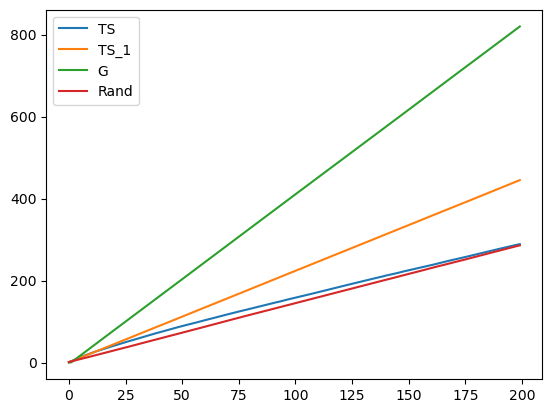

In [749]:
y_ = y.copy()
y_[::-1].sort(0)

probs_TS = (pd.DataFrame(results_TS).groupby(['t']).mean()).reset_index()#.sum(1)
probs_TS_1 = (pd.DataFrame(results_TS_1).groupby(['t']).mean()).reset_index()#.sum(1)
probs_G = (pd.DataFrame(results_G).groupby(['t']).mean()).reset_index()#.sum(1)
probs_Rand = (pd.DataFrame(results_Rand).groupby(['t']).mean()).reset_index()#.sum(1)

plt.plot(probs_TS['t'], probs_TS['rw'], label='TS')
plt.plot(probs_TS_1['t'], probs_TS_1['rw'], label='TS_1')
plt.plot(probs_G['t'], probs_G['rw'], label='G')
plt.plot(probs_Rand['t'], probs_Rand['rw'], label='Rand')
#plt.plot(probs_TS['t'], y_.flatten().cumsum(), label='Perfect')
plt.legend()

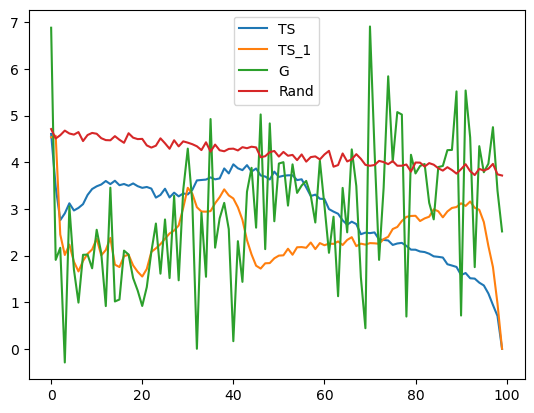

In [715]:
y_ = y.copy()
y_[::-1].sort(0)

probs_TS = (pd.DataFrame(results_TS).groupby(['t']).mean()).reset_index()#.sum(1)
probs_TS_1 = (pd.DataFrame(results_TS_1).groupby(['t']).mean()).reset_index()#.sum(1)
probs_G = (pd.DataFrame(results_G).groupby(['t']).mean()).reset_index()#.sum(1)
probs_Rand = (pd.DataFrame(results_Rand).groupby(['t']).mean()).reset_index()#.sum(1)

plt.plot(probs_TS['t'], probs_TS['regret_t'], label='TS')
plt.plot(probs_TS_1['t'], probs_TS_1['regret_t'], label='TS_1')
plt.plot(probs_G['t'], probs_G['regret_t'], label='G')
plt.plot(probs_Rand['t'], probs_Rand['regret_t'], label='Rand')
#plt.plot(probs_TS['t'], y_.flatten().cumsum(), label='Perfect')
plt.legend()